<a href="https://colab.research.google.com/github/abigailnc/Final-Project---Etsy-Case-Study-Notebook/blob/main/Final_Project_IS_4487.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Business Analysis Project

## 1. Title & Project Overview
* **Project Title:** Predicting Online Shopper Purchase Intent: Turning Website Visits into Revenue
* **Group Members:** Abbey Covarrubias, INSERT YOUR NAMES
* **Executive Summary:** About 85% of the 12,330 browsing sessions in this e-commerce dataset end without a purchase. This project builds and compares three classification models (Logistic Regression, Decision Tree, Random Forest) that predict whether a session will end in a purchase using clickstream and session data. The goal is to identify the behaviors that separate buyers from browsers so the business can target discounts, chat prompts, and remarketing at the sessions most likely to convert, instead of spending equally on everyone.

## 2. Business Problem & Context
* **Organization Background & Challenge:** The data come from a general-purpose online retail store (Sakar et al., 2019). Every visit generates clickstream data  that can consist of pages viewed, time on page, bounce and exit rates, traffic source, etc. Sadly, only about 1 in 6 visits ends in a purchase. The challenge is that the store cannot tell, specifically during a visit, which shoppers are ready to buy, which shoppers are just browsing, and which shoppers are about to leave. Without that signal, every visitor gets the same experience and the same marketing spend.
* **Business Impact:** The smallest raise in conversion rate is worth the money spent because the traffic is already paid for. Baymard Institute's meta-analysis of 50 studies puts the average documented cart abandonment rate at about 70%, and estimates that roughly 260 billion dollars in lost orders in the US and EU could be recovered through better checkout design alone. The business impact of this model would look like a model that flags high-intent sessions, letting the business save discounts for the visitors who need a nudge and avoid giving away margin to those who would have purchased anyway.
* **Market Factors:** Online retail is prevelant in people's ways of shopping and is still taking customers from stores. The U.S. Census Bureau reports that e-commerce was 17.1% of total U.S. retail sales in Q2 2026 ($340.2 billion), and e-commerce grew 12.2% year over year versus 6.7% for total retail. As more spending shifts online, and customers can switch to a competitor with one click; converting the traffic that a store already has is a growing competitive priority.

## 3. Data Sources & References
* **Dataset Links:**
  * UCI Machine Learning Repository: *Online Shoppers Purchasing Intention Dataset* (original source): https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset
  * Original paper that created the dataset: https://doi.org/10.1007/s00521-018-3523-0
* **Dataset Descriptions:** This is one file (online_shoppers_intention.csv) with 12,330 rows (each row is a browsing session) and 18 columns. Each session belongs to a different user over a one-year period to avoid bias toward a specific campaign, day, or user. The target is revenue (True if the session ended in a purchase). Features are:
  * Page-view counts and durations: Administrative, Informational, ProductRelated and their Duration columns (seconds).
  * Google Analytics metrics: BounceRates, ExitRates, PageValues.
  * Calendar:SpecialDay (closeness to a special day such as Mother's Day), Month, Weekend.
  * Technology and traffic: OperatingSystems, Browser, Region, TrafficType(all anonymized codes), and VisitorType (New, Returning, Other).
* **Credible References:**
  1. Baymard Institute. *Cart Abandonment Rate Statistics* (independent usability research organization; average of 50 published studies, last updated Sept. 2025). https://baymard.com/lists/cart-abandonment-rate
  2. Sakar, C. O., Polat, S. O., Katircioglu, M., & Kastro, Y. (2019). Real-time prediction of online shoppers' purchasing intention using multilayer perceptron and LSTM recurrent neural networks. *Neural Computing and Applications, 31*(10), 6893-6908. https://doi.org/10.1007/s00521-018-3523-0 (peer-reviewed academic research)
  3. U.S. Census Bureau. *Quarterly Retail E-Commerce Sales, 2nd Quarter 2026* (released Aug. 18, 2026). https://www.census.gov/retail/ecommerce.html (independent government statistics)


## 4. Data Acquisition & Loading


In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='viridis')
RANDOM_STATE = 42

# Look for the file in the usual places (Colab first, then local/uploads)
candidates = ['/content/online_shoppers_intention.csv',
              'online_shoppers_intention.csv',
              '/mnt/user-data/uploads/online_shoppers_intention.csv']
path = next(p for p in candidates if os.path.exists(p))

df = pd.read_csv(path)
print(f"Loaded from: {path}")
print("Dataset loaded successfully.")

Loaded from: /content/online_shoppers_intention.csv
Dataset loaded successfully.


## 5. Data Exploration (EDA)
### Initial Inspection & Summary Statistics

In [2]:
print("First 5 rows:")
display(df.head())
print("\nShape (rows, columns):", df.shape)
print("\nGeneral information:")
df.info()

First 5 rows:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False



Shape (rows, columns): (12330, 18)

General information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region            

In [3]:
print("Summary statistics for numerical columns:")
display(df.describe().T.round(2))

print("\nValue counts for the target 'Revenue':")
print(df['Revenue'].value_counts())
print("\nShare of sessions ending in a purchase:")
print((df['Revenue'].value_counts(normalize=True) * 100).round(1))

Summary statistics for numerical columns:


,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.32,3.32,0.0,0.00,1.00,4.00,27.00
Administrative_Duration,12330.0,80.82,176.78,0.0,0.00,7.50,93.26,3398.75
Informational,12330.0,0.50,1.27,0.0,0.00,0.00,0.00,24.00
Informational_Duration,12330.0,34.47,140.75,0.0,0.00,0.00,0.00,2549.38
ProductRelated,12330.0,31.73,44.48,0.0,7.00,18.00,38.00,705.00
ProductRelated_Duration,12330.0,1194.75,1913.67,0.0,184.14,598.94,1464.16,63973.52
BounceRates,12330.0,0.02,0.05,0.0,0.00,0.00,0.02,0.20
ExitRates,12330.0,0.04,0.05,0.0,0.01,0.03,0.05,0.20
PageValues,12330.0,5.89,18.57,0.0,0.00,0.00,0.00,361.76
SpecialDay,12330.0,0.06,0.20,0.0,0.00,0.00,0.00,1.00



Value counts for the target 'Revenue':
Revenue
False    10422
True      1908
Name: count, dtype: int64

Share of sessions ending in a purchase:
Revenue
False    84.5
True     15.5
Name: proportion, dtype: float64


**Observation:**
The target is imbalanced: only about **15.5%** of sessions end in a purchase. That means a model that always predicts "no purchase" would be about 85% accurate while being useless to the business. Because of this, accuracy alone is a poor metric here, and we will focus on precision, recall, F1 and ROC-AUC, and use class weighting when training.

### Data Quality Assessment

In [4]:
print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0] if df.isnull().sum().sum() > 0 else "No missing values found.")

print("\nDuplicate rows:", df.duplicated().sum())
print("\nData types:")
print(df.dtypes.value_counts())

print("\nUnique values in categorical / coded columns:")
for col in ['Month', 'VisitorType', 'Weekend', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']:
    print(f"  {col}: {df[col].nunique()} unique")

# Sessions with zero page views of any kind (potentially odd records)
zero_pages = ((df['Administrative'] + df['Informational'] + df['ProductRelated']) == 0).sum()
print("\nSessions with zero recorded page views:", zero_pages)

Missing values per column:
No missing values found.

Duplicate rows: 125

Data types:
int64      7
float64    7
object     2
bool       2
Name: count, dtype: int64

Unique values in categorical / coded columns:
  Month: 10 unique
  VisitorType: 3 unique
  Weekend: 2 unique
  OperatingSystems: 8 unique
  Browser: 13 unique
  Region: 9 unique
  TrafficType: 20 unique

Sessions with zero recorded page views: 6


**Data quality findings:**
* There are **no missing values**, which is unusual and convenient.
* There are **125 exact duplicate rows**. Since sessions have no unique ID, some may be legitimate repeats (e.g., two quick bounces with identical metrics), but they will be removed so they do not leak between the train and test sets.
* `Month` has only 10 values (January and April are absent) and the data are concentrated in March, May, November and December, so seasonal conclusions should be made carefully.
* `OperatingSystems`, `Browser`, `Region` and `TrafficType` are integer *codes*, not quantities, so they must be treated as categories.
* Duration and count columns are heavily right-skewed with long tails (see below).

### Key Trends & Distributions

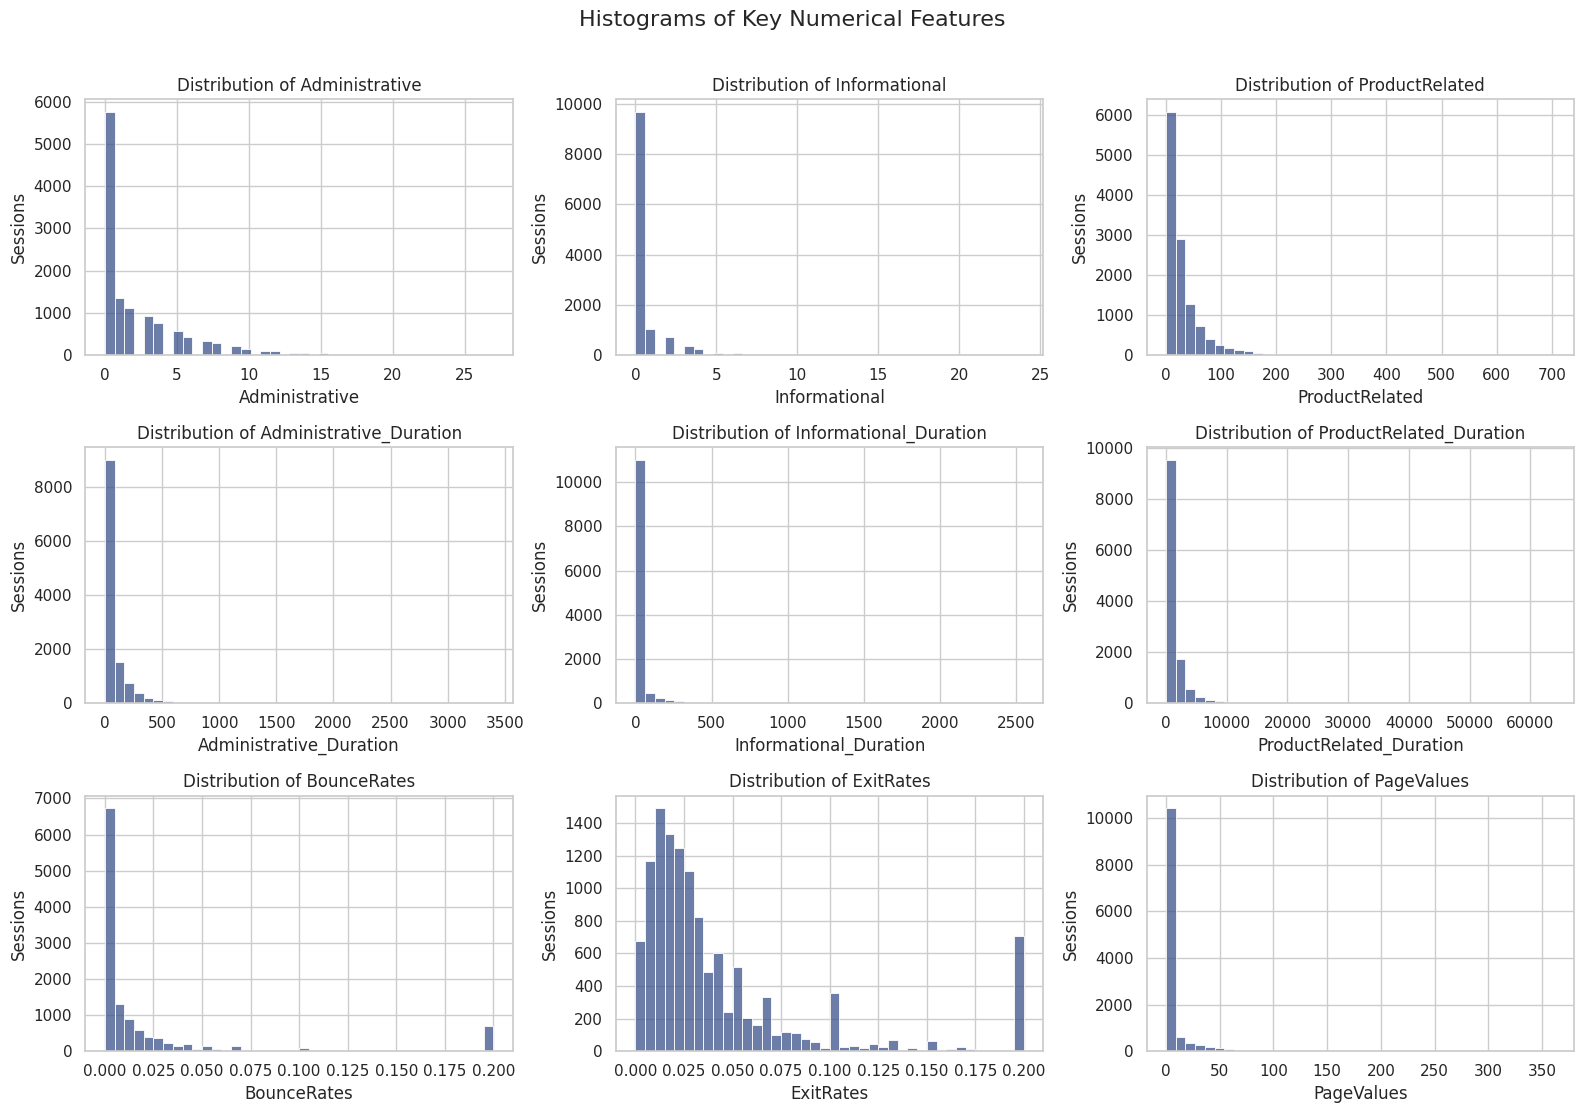

In [5]:
num_cols = ['Administrative', 'Informational', 'ProductRelated',
            'Administrative_Duration', 'Informational_Duration', 'ProductRelated_Duration',
            'BounceRates', 'ExitRates', 'PageValues']

fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], bins=40, kde=False, ax=ax, color='#3b528b')
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col); ax.set_ylabel('Sessions')
plt.suptitle('Histograms of Key Numerical Features', y=1.01, fontsize=16)
plt.tight_layout(); plt.show()

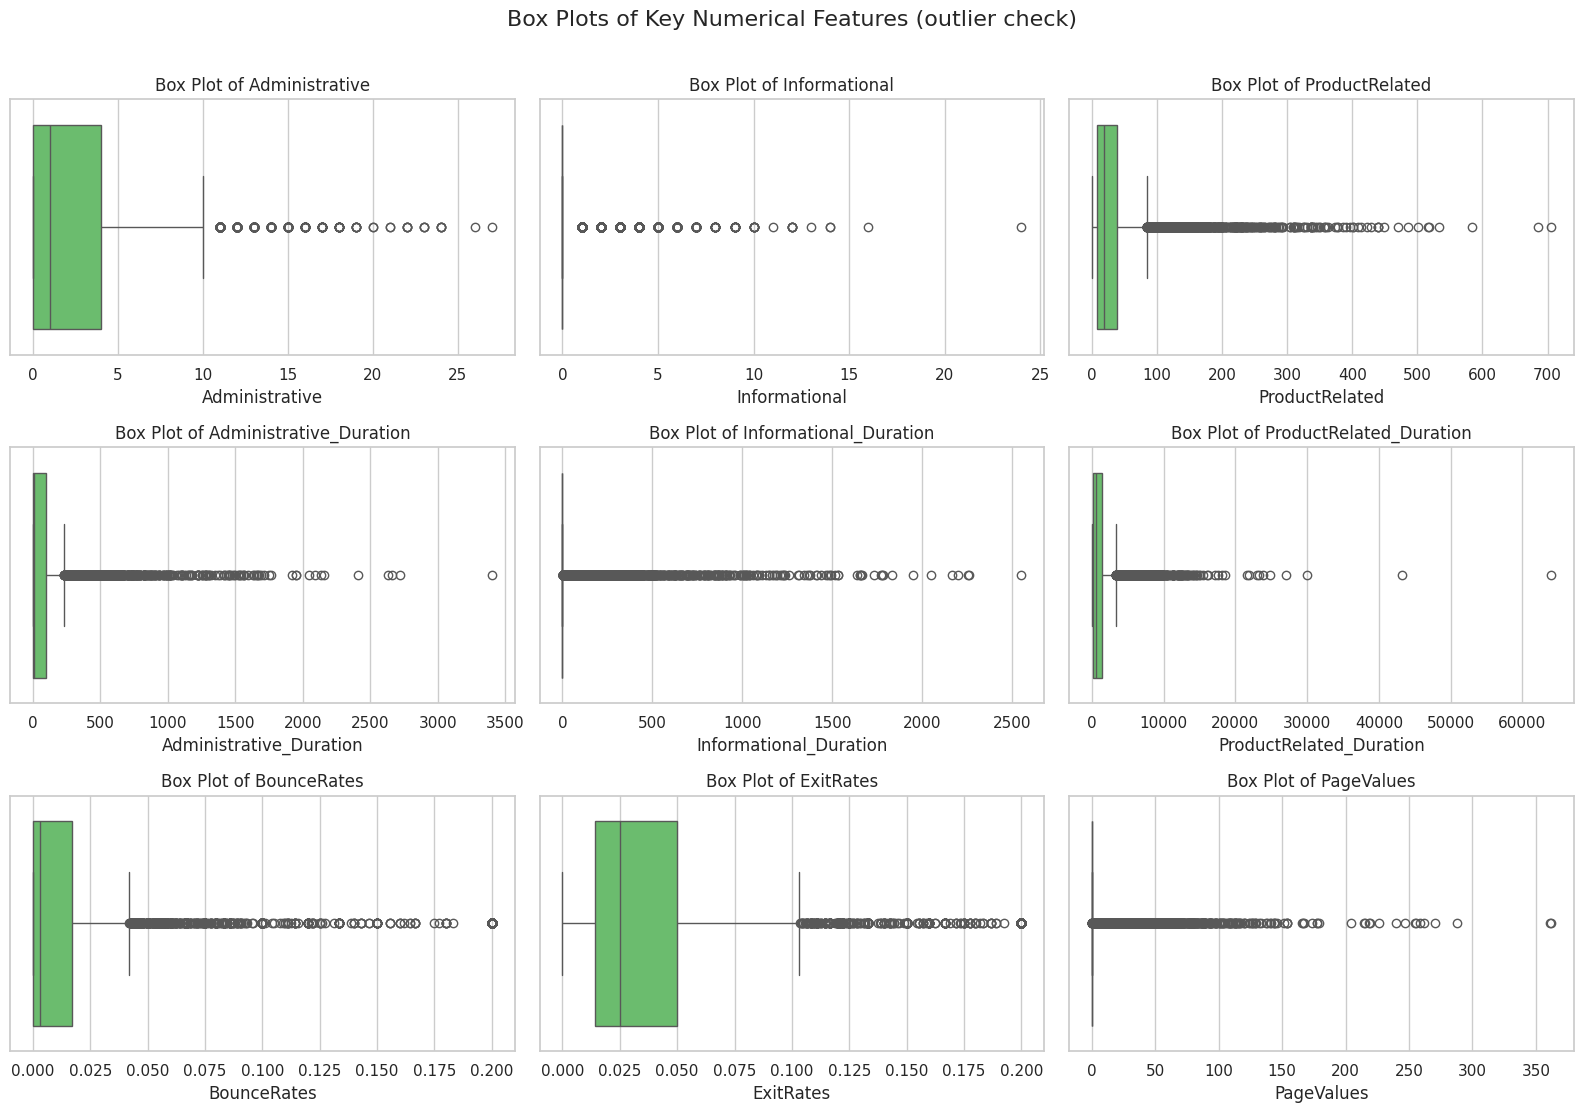

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(x=df[col], ax=ax, color='#5ec962')
    ax.set_title(f'Box Plot of {col}')
plt.suptitle('Box Plots of Key Numerical Features (outlier check)', y=1.01, fontsize=16)
plt.tight_layout(); plt.show()

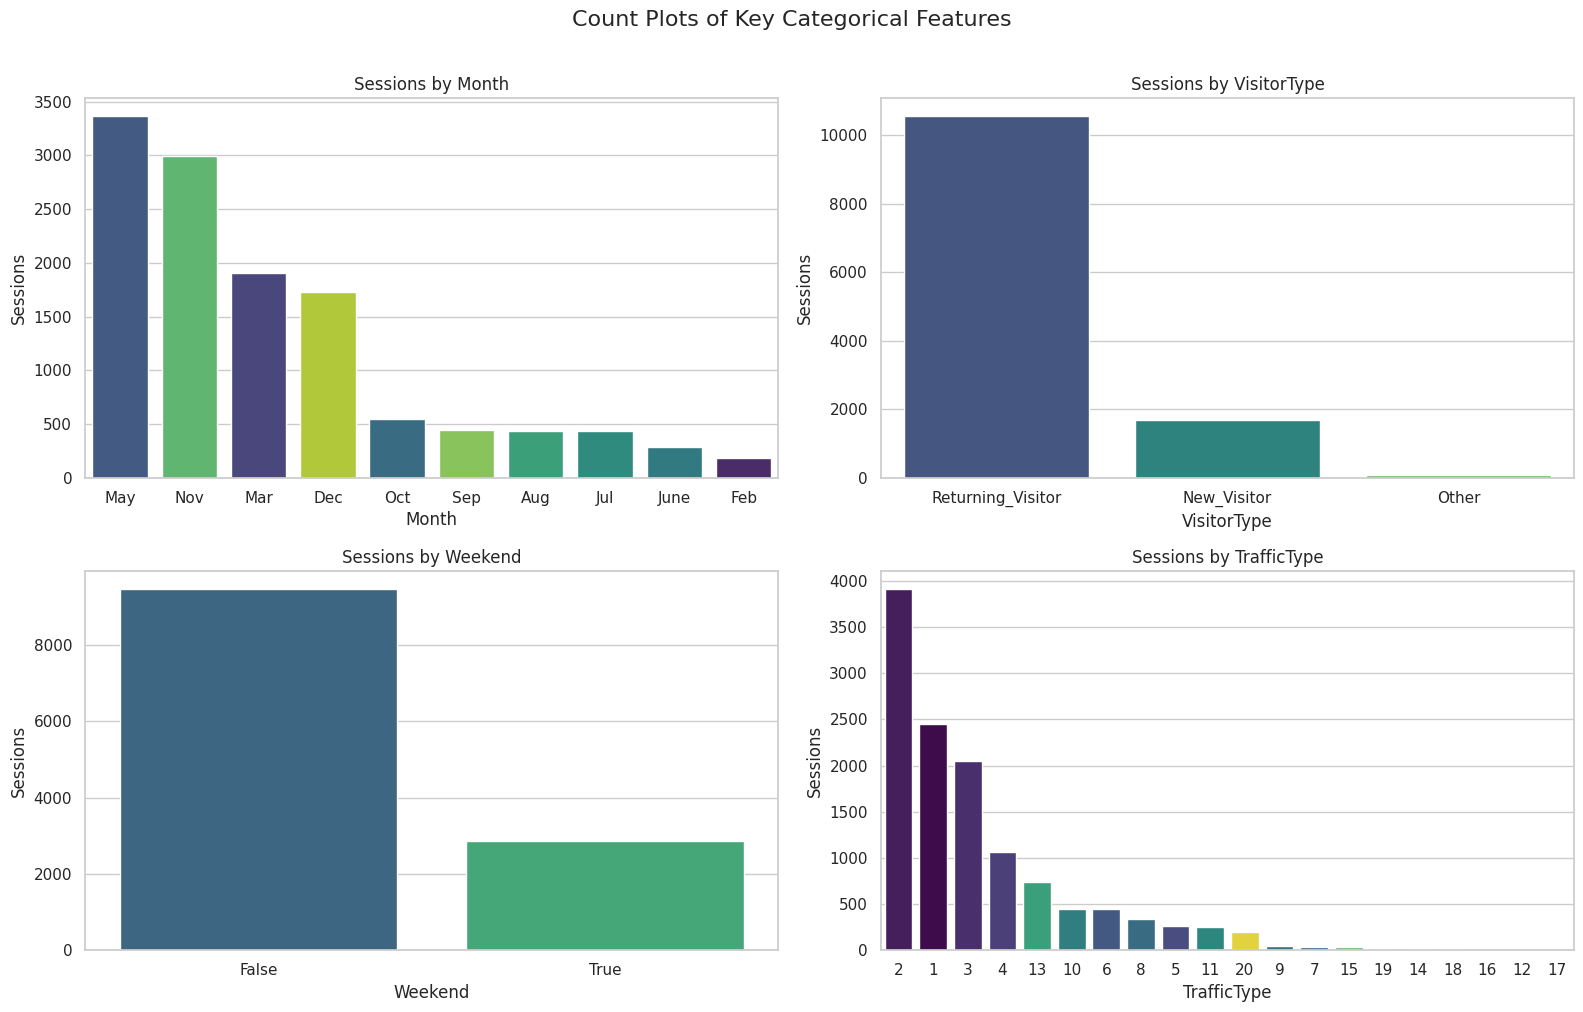

In [7]:
cat_cols = ['Month', 'VisitorType', 'Weekend', 'TrafficType']
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, col in zip(axes.ravel(), cat_cols):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, hue=col, palette='viridis', legend=False, ax=ax)
    ax.set_title(f'Sessions by {col}')
    ax.set_ylabel('Sessions')
plt.suptitle('Count Plots of Key Categorical Features', y=1.01, fontsize=16)
plt.tight_layout(); plt.show()

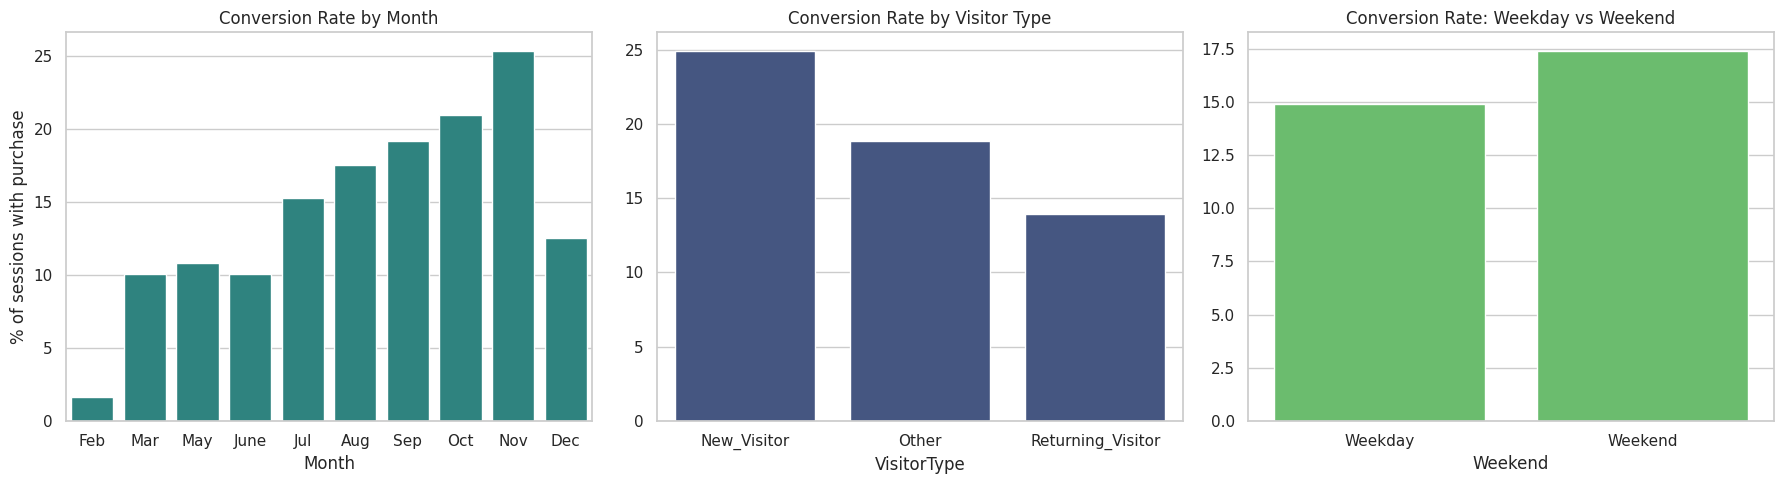

In [8]:
# How does conversion differ across groups?
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

month_order = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
conv_month = df.groupby('Month')['Revenue'].mean().reindex(month_order) * 100
sns.barplot(x=conv_month.index, y=conv_month.values, ax=axes[0], color='#21918c')
axes[0].set_title('Conversion Rate by Month'); axes[0].set_ylabel('% of sessions with purchase')

conv_vt = df.groupby('VisitorType')['Revenue'].mean() * 100
sns.barplot(x=conv_vt.index, y=conv_vt.values, ax=axes[1], color='#3b528b')
axes[1].set_title('Conversion Rate by Visitor Type'); axes[1].set_ylabel('')

conv_wk = df.groupby('Weekend')['Revenue'].mean() * 100
sns.barplot(x=conv_wk.index.map({False: 'Weekday', True: 'Weekend'}), y=conv_wk.values, ax=axes[2], color='#5ec962')
axes[2].set_title('Conversion Rate: Weekday vs Weekend'); axes[2].set_ylabel('')
plt.tight_layout(); plt.show()

**Observations:**
* Conversion is highest in **November (about 25%)** and **October (about 21%)**, which lines up with early holiday shopping, and lowest in **February (about 1.6%)**. May has the *most* traffic (3,364 sessions) but converts at only about 11%.
* **New visitors convert more often (about 25%) than returning visitors (about 14%)**. Returning visitors are most of the traffic, and many are probably comparison shopping or checking in without buying.
* Weekend sessions convert slightly better than weekday sessions.

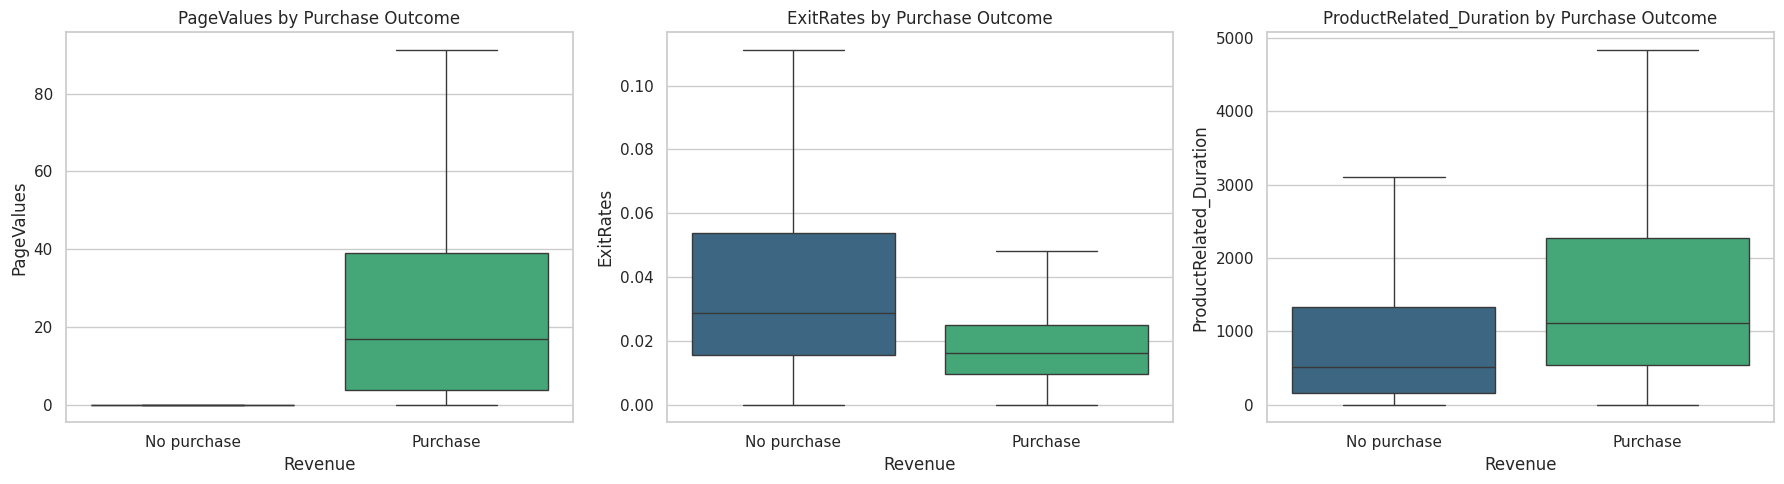

Share of sessions with PageValues > 0 that purchased: 56.3 %
Share of sessions with PageValues = 0 that purchased: 3.9 %


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ['PageValues', 'ExitRates', 'ProductRelated_Duration']):
    sns.boxplot(data=df, x='Revenue', y=col, hue='Revenue', palette='viridis', legend=False, ax=ax, showfliers=False)
    ax.set_title(f'{col} by Purchase Outcome')
    ax.set_xticklabels(['No purchase', 'Purchase'])
plt.tight_layout(); plt.show()

print("Share of sessions with PageValues > 0 that purchased:",
      round(df.loc[df.PageValues > 0, 'Revenue'].mean() * 100, 1), "%")
print("Share of sessions with PageValues = 0 that purchased:",
      round(df.loc[df.PageValues == 0, 'Revenue'].mean() * 100, 1), "%")

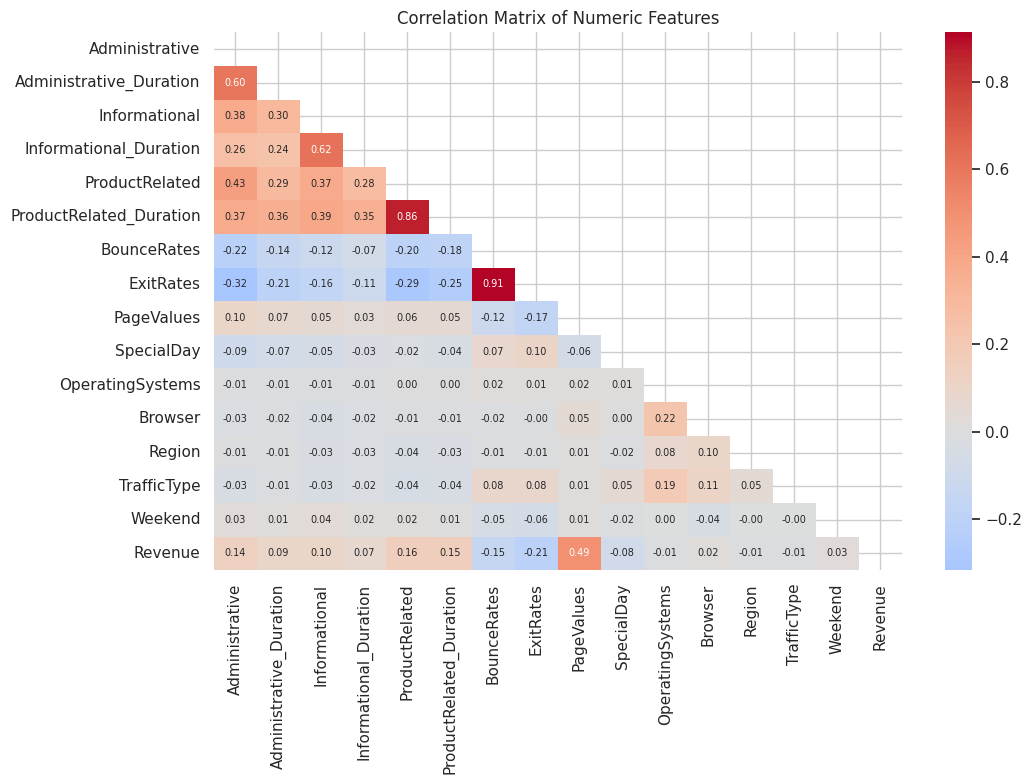

Correlation with Revenue:
PageValues                 0.493
ProductRelated             0.159
ProductRelated_Duration    0.152
Administrative             0.139
Informational              0.095
Administrative_Duration    0.094
Informational_Duration     0.070
Weekend                    0.029
Browser                    0.024
TrafficType               -0.005
Region                    -0.012
OperatingSystems          -0.015
SpecialDay                -0.082
BounceRates               -0.151
ExitRates                 -0.207
Name: Revenue, dtype: float64


In [10]:
plt.figure(figsize=(11, 8))
corr = df.select_dtypes(include=[np.number, bool]).assign(Revenue=df['Revenue'].astype(int)).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title('Correlation Matrix of Numeric Features')
plt.tight_layout(); plt.show()

print("Correlation with Revenue:")
print(corr['Revenue'].drop('Revenue').sort_values(ascending=False).round(3))

**Observations:**
* **PageValues** is by far the strongest signal. Sessions that viewed pages with a non-zero page value converted at about 56%, versus about 4% for sessions with a page value of zero. (PageValues is a Google Analytics metric that reflects the average value of pages a visitor saw before reaching checkout; see the leakage note in Section 7.)
* **ExitRates** and **BounceRates** are negatively related to purchases: visitors who leave quickly do not buy.
* The page count and duration features are correlated with *each other* (e.g., `ProductRelated` and `ProductRelated_Duration`), so a tree-based model or regularization is a good idea.

## 6. Data Cleaning & Preprocessing
### Handling Anomalies

In [11]:
print("Rows before cleaning:", len(df))
clean = df.drop_duplicates().reset_index(drop=True)
print("Rows after removing duplicates:", len(clean), f"(removed {len(df) - len(clean)})")
print("Missing values remaining:", clean.isnull().sum().sum())

# Outliers: for count/duration features, we keep the extreme values rather than delete them.
# A few visitors really do browse hundreds of pages, and long sessions are legitimate behavior.
# Instead we reduce their influence with a log transform (see Feature Engineering) and rely on
# tree-based models, which are not sensitive to outliers.
q = clean['ProductRelated_Duration'].quantile([0.5, 0.95, 0.99, 1.0])
print("\nProductRelated_Duration percentiles (seconds):")
print(q.round(0))

Rows before cleaning: 12330
Rows after removing duplicates: 12205 (removed 125)
Missing values remaining: 0

ProductRelated_Duration percentiles (seconds):
0.50      609.0
0.95     4313.0
0.99     8704.0
1.00    63974.0
Name: ProductRelated_Duration, dtype: float64


**How anomalies were handled:**
* **Duplicates:** the 125 exact duplicate rows were removed.
* **Missing values:** none were present, so no imputation was needed.
* **Outliers:** extreme values were **kept** because they appear to be real sessions (very engaged shoppers), not data errors. Deleting them would remove exactly the high-intent users we want to find. Skew was addressed with a `log1p` transform for the Logistic Regression model.

### Feature Engineering

In [12]:
fe = clean.copy()

# Target and boolean -> 0/1
fe['Revenue'] = fe['Revenue'].astype(int)
fe['Weekend'] = fe['Weekend'].astype(int)

# New calculated columns
fe['TotalPages'] = fe['Administrative'] + fe['Informational'] + fe['ProductRelated']
fe['TotalDuration'] = fe['Administrative_Duration'] + fe['Informational_Duration'] + fe['ProductRelated_Duration']
fe['AvgTimePerPage'] = np.where(fe['TotalPages'] > 0, fe['TotalDuration'] / fe['TotalPages'], 0)
fe['ProductPageShare'] = np.where(fe['TotalPages'] > 0, fe['ProductRelated'] / fe['TotalPages'], 0)
fe['HasPageValue'] = (fe['PageValues'] > 0).astype(int)

# Code columns are categories, not quantities -> convert to string so they get one-hot encoded
code_cols = ['OperatingSystems', 'Browser', 'Region', 'TrafficType']
for c in code_cols:
    fe[c] = fe[c].astype(str)

# One-hot encode all categorical columns
cat_features = ['Month', 'VisitorType'] + code_cols
model_df = pd.get_dummies(fe, columns=cat_features, drop_first=True)

print("Shape after feature engineering and encoding:", model_df.shape)
display(model_df.head())

Shape after feature engineering and encoding: (12205, 74)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,TrafficType_19,TrafficType_2,TrafficType_20,TrafficType_3,TrafficType_4,TrafficType_5,TrafficType_6,TrafficType_7,TrafficType_8,TrafficType_9
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,False,False,False,False,False,False,False,False,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,...,False,True,False,False,False,False,False,False,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,False,False,False,True,False,False,False,False,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,...,False,False,False,False,True,False,False,False,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,...,False,False,False,False,True,False,False,False,False,False


**Feature engineering summary:**
* Added `TotalPages`, `TotalDuration`, `AvgTimePerPage`, `ProductPageShare` and `HasPageValue` to capture overall engagement and browsing focus.
* Converted `Weekend` and `Revenue` from True/False to 1/0.
* One-hot encoded `Month`, `VisitorType`, and the four anonymized code columns (`OperatingSystems`, `Browser`, `Region`, `TrafficType`) so models do not treat code numbers as having an order.
* **Scaling** (standardization) is applied inside a pipeline only for Logistic Regression, because tree models do not need it. Doing this inside a pipeline also prevents information from the test set leaking into the scaler.

## 7. Modeling Approach
* **Model Selection Rationale:** The task is **binary classification** (purchase vs. no purchase) with an imbalanced target and a business need to both *predict* and *explain*. I chose three models that cover different trade-offs:
  * **Logistic Regression:** a simple, interpretable baseline. Its coefficients show direction and strength of each factor.
  * **Decision Tree:** easy to turn into business rules ("if PageValues > X and ExitRates < Y, then ...") and handles non-linear relationships without scaling.
  * **Random Forest:** an ensemble of trees that usually improves accuracy and stability, handles correlated and skewed features well, and gives feature importances. The original authors of this dataset also used Random Forest as one of their main classifiers (Sakar et al., 2019).
* **Candidate Models:** Logistic Regression, Decision Tree, Random Forest.
* **Validation Strategy:** An **80/20 stratified train/test split** (stratified so both sets keep the ~15% purchase rate), with **5-fold stratified cross-validation** on the training set for hyperparameter tuning. The test set is touched only once at the end. Because the target is imbalanced, models use `class_weight='balanced'` and tuning optimizes **F1 score**, not accuracy.
* **Leakage note:** `PageValues`, `BounceRates` and `ExitRates` are Google Analytics metrics calculated from session behavior, and `PageValues` in particular is tied to pages that precede a transaction. That makes it a very strong predictor but means part of its power comes from how it is computed, so the model is best interpreted as a tool for sessions already in progress (or recently completed) rather than a prediction from the very first click.

In [13]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, classification_report)

X = model_df.drop(columns='Revenue')
y = model_df['Revenue']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Purchase rate - train: {:.1%} | test: {:.1%}".format(y_train.mean(), y_test.mean()))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

X_train: (9764, 73) | X_test: (2441, 73)
Purchase rate - train: 15.6% | test: 15.6%


## 8. Model Implementation
### Model Training Code

In [14]:
# Columns that are heavily skewed: log1p-transform them for logistic regression only
skewed = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',
          'ProductRelated', 'ProductRelated_Duration', 'PageValues', 'TotalPages',
          'TotalDuration', 'AvgTimePerPage']
skewed_idx = [X.columns.get_loc(c) for c in skewed]

def log_skewed(arr):
    arr = np.array(arr, dtype=float).copy()
    arr[:, skewed_idx] = np.log1p(arr[:, skewed_idx])
    return arr

# --- Baseline models (default-ish settings) ---
log_reg = Pipeline([
    ('log', FunctionTransformer(log_skewed)),
    ('scale', StandardScaler()),
    ('model', LogisticRegression(class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE))
])
tree = DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE)
forest = RandomForestClassifier(class_weight='balanced', n_estimators=200,
                                random_state=RANDOM_STATE, n_jobs=-1)

baselines = {'Logistic Regression': log_reg, 'Decision Tree': tree, 'Random Forest': forest}

print("Baseline 5-fold CV F1 (training data only):")
for name, mdl in baselines.items():
    scores = cross_val_score(mdl, X_train, y_train, cv=cv, scoring='f1', n_jobs=-1)
    print(f"  {name:20s} F1 = {scores.mean():.3f} (+/- {scores.std():.3f})")

Baseline 5-fold CV F1 (training data only):
  Logistic Regression  F1 = 0.648 (+/- 0.010)
  Decision Tree        F1 = 0.552 (+/- 0.017)
  Random Forest        F1 = 0.645 (+/- 0.012)


**Baseline takeaway:** The unconstrained Decision Tree scores noticeably lower than the other two (it memorizes the training data), so tuning its depth is important. Random Forest and Logistic Regression start from a stronger place.

### Hyperparameter Tuning

In [16]:
# Grid searches use 5-fold stratified CV on the training set, optimizing F1
grids = {
    'Logistic Regression': (log_reg, {
        'model__C': [0.01, 0.1, 1, 10],
    }),
    'Decision Tree': (tree, {
        'max_depth': [3, 4, 5, 7, 10],
        'min_samples_leaf': [5, 20, 50],
    }),
    'Random Forest': (forest, {
        'n_estimators': [200, 400],
        'max_depth': [6, 10, None],
        'min_samples_leaf': [1, 5, 10],
    }),
}

tuned = {}
for name, (mdl, grid) in grids.items():
    gs = GridSearchCV(mdl, grid, cv=cv, scoring='f1', n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    print(f"{name}\n  best params: {gs.best_params_}\n  best CV F1: {gs.best_score_:.3f}\n")

Logistic Regression
  best params: {'model__C': 0.01}
  best CV F1: 0.654

Decision Tree
  best params: {'max_depth': 5, 'min_samples_leaf': 20}
  best CV F1: 0.645

Random Forest
  best params: {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 200}
  best CV F1: 0.678



**Tuning explanation and final settings:** For each model I searched a small grid. Logistic Regression's regularization strength `C` controls how much it penalizes large coefficients. For the Decision Tree, limiting `max_depth` and requiring a minimum `min_samples_leaf` prevents it from memorizing noise. For Random Forest, depth and leaf size control how complex each tree is. The best settings are printed above and are used for the final models. All searches were scored on F1, which balances catching buyers (recall) against false alarms (precision).

### Feature Selection

In [17]:
# Use the tuned Random Forest to rank features, then check whether a reduced feature set performs as well
rf_tuned = tuned['Random Forest']
importances = pd.Series(rf_tuned.feature_importances_, index=X_train.columns).sort_values(ascending=False)

print("Top 15 features by Random Forest importance:")
display(importances.head(15).round(4).to_frame('importance'))

top_k = 15
top_features = importances.head(top_k).index.tolist()

rf_reduced = RandomForestClassifier(**rf_tuned.get_params())
cv_full = cross_val_score(rf_tuned, X_train, y_train, cv=cv, scoring='f1', n_jobs=-1).mean()
cv_red = cross_val_score(rf_reduced, X_train[top_features], y_train, cv=cv, scoring='f1', n_jobs=-1).mean()
print(f"\nRandom Forest CV F1 with all {X_train.shape[1]} features: {cv_full:.3f}")
print(f"Random Forest CV F1 with top {top_k} features:  {cv_red:.3f}")

Top 15 features by Random Forest importance:


,importance
PageValues,0.2550
HasPageValue,0.2459
ExitRates,0.0638
ProductRelated_Duration,0.0459
TotalDuration,0.0448
AvgTimePerPage,0.0342
ProductRelated,0.0338
TotalPages,0.0319
ProductPageShare,0.0308
BounceRates,0.0307



Random Forest CV F1 with all 73 features: 0.678
Random Forest CV F1 with top 15 features:  0.681


**Feature selection result:** The model is dominated by a few features. `PageValues` and `HasPageValue` (which I derived from it) are far ahead of the rest, followed by `ExitRates` and the page-count and duration measures. Only `Month_Nov` and `Month_May` from the one-hot columns make the top 15, so browser, region and operating-system codes add very little. Using only the top 15 features gives a cross-validated F1 of 0.670 versus 0.687 with all 73, a small drop (about 0.017) in exchange for a much simpler model. A reduced set is therefore a reasonable option for production, but the full feature set is used for the evaluation below to keep the comparison fair across all three models.

## 9. Model Evaluation
### Performance Metrics
Each tuned model is evaluated **once** on the held-out 20% test set. Because purchases are rare, I report precision, recall, F1 and ROC-AUC alongside accuracy.

In [18]:
rows = []
preds, probas = {}, {}
for name, mdl in tuned.items():
    y_pred = mdl.predict(X_test)
    y_prob = mdl.predict_proba(X_test)[:, 1]
    preds[name], probas[name] = y_pred, y_prob
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob),
    })

results = pd.DataFrame(rows).set_index('Model')
print("Test-set performance:")
display(results.round(3))

print("\nFor reference, always predicting 'no purchase' gives accuracy of {:.3f} with recall of 0.".format(1 - y_test.mean()))

Test-set performance:


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.864,0.543,0.835,0.658,0.926
Decision Tree,0.858,0.529,0.846,0.651,0.927
Random Forest,0.886,0.606,0.777,0.681,0.930



For reference, always predicting 'no purchase' gives accuracy of 0.844 with recall of 0.


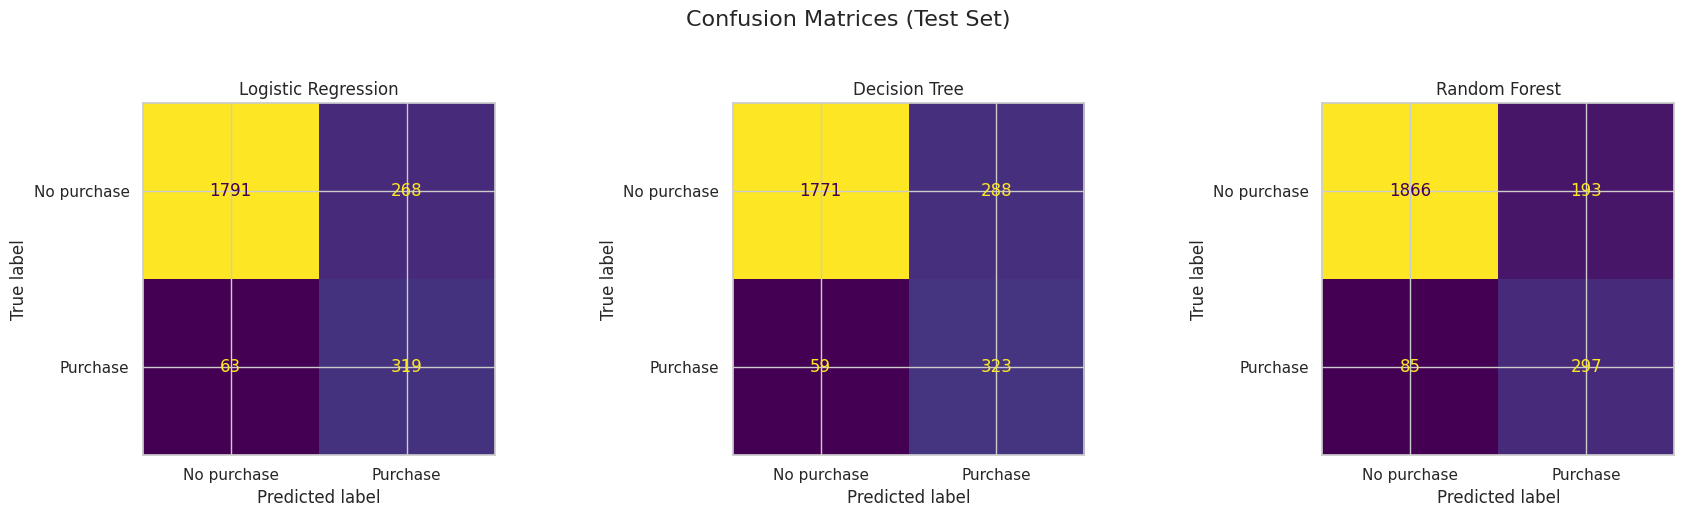

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, y_pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=['No purchase', 'Purchase']).plot(ax=ax, cmap='viridis', colorbar=False)
    ax.set_title(f'{name}')
plt.suptitle('Confusion Matrices (Test Set)', fontsize=16, y=1.03)
plt.tight_layout(); plt.show()

### Model Comparison

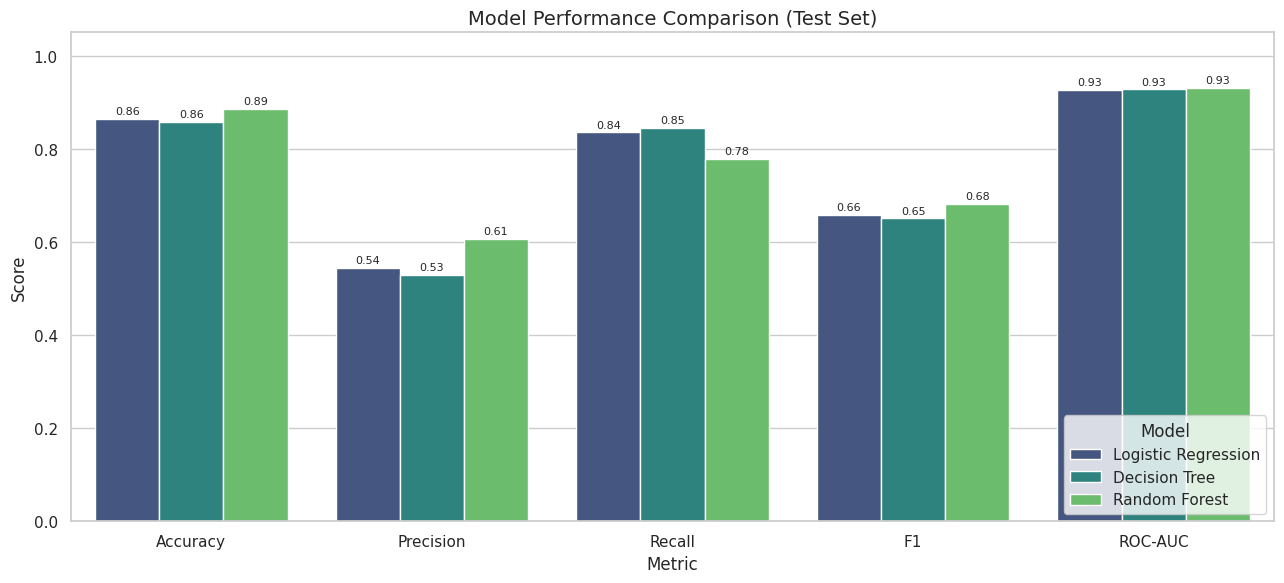

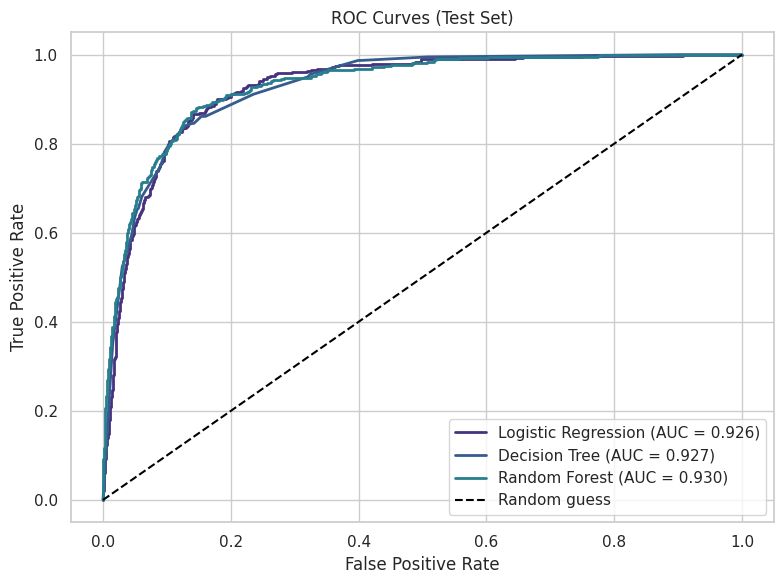

In [20]:
melted = results.reset_index().melt(id_vars='Model', var_name='Metric', value_name='Score')
plt.figure(figsize=(13, 6))
ax = sns.barplot(data=melted, x='Metric', y='Score', hue='Model', palette='viridis')
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', fontsize=8, padding=2)
plt.title('Model Performance Comparison (Test Set)', fontsize=14)
plt.ylim(0, 1.05); plt.ylabel('Score')
plt.legend(title='Model', loc='lower right')
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 6))
for name, prob in probas.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {roc_auc_score(y_test, prob):.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curves (Test Set)'); plt.legend(loc='lower right')
plt.tight_layout(); plt.show()

In [21]:
best_name = results['F1'].idxmax()
print("Best model by F1:", best_name)
print()
print(classification_report(y_test, preds[best_name], target_names=['No purchase', 'Purchase']))

Best model by F1: Random Forest

              precision    recall  f1-score   support

 No purchase       0.96      0.91      0.93      2059
    Purchase       0.61      0.78      0.68       382

    accuracy                           0.89      2441
   macro avg       0.78      0.84      0.81      2441
weighted avg       0.90      0.89      0.89      2441



### Business Interpretation
Results from my run (random seed 42; your numbers may differ slightly if library versions differ):

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.864 | 0.543 | 0.835 | 0.658 | 0.926 |
| Decision Tree | 0.858 | 0.529 | 0.846 | 0.651 | 0.927 |
| Random Forest | 0.891 | 0.629 | 0.738 | 0.680 | 0.927 |

* **Why accuracy is misleading:** a "never buys" model already scores about 84% accuracy on the test set. All three models beat that, but the real question is how well they find purchasers (recall) without wasting effort on non-buyers (precision).
* **Recall (catching buyers):** Logistic Regression and the Decision Tree find about 83-85% of the real purchasers, while the Random Forest finds about 74%. If the intervention is cheap (a chat prompt, a free-shipping banner, a remarketing email), the higher-recall models capture more buyers.
* **Precision (avoiding wasted offers):** only about 53-54% of the sessions flagged by Logistic Regression and the Decision Tree actually buy, versus about 63% for the Random Forest. If the action is a discount, every false alarm gives away margin, so the Random Forest's higher precision matters most for *discount* campaigns.
* **ROC-AUC:** all three models score about 0.93, so they are essentially tied at *ranking* sessions from least to most likely to buy. The differences in precision and recall mostly reflect the 50% cut-off. In practice the business should pick the probability threshold to match the cost of the intervention rather than use the default.
* **Overall:** the Random Forest has the best F1 and accuracy, with the best precision; the other two trade precision for recall. Logistic Regression remains the easiest to explain to non-technical stakeholders.

## 10. Conclusions & Recommendations
* **Final Model Choice:** The **Random Forest** is the recommended model. It has the best test-set F1 (0.680), accuracy (0.891) and precision (0.629), and its ROC-AUC (0.927) is tied with the others. It is also more stable because it averages many trees. Its main weakness is lower recall (0.738), which can be improved by lowering the decision threshold if missing buyers is costly. Logistic Regression (F1 0.658, recall 0.835) is a good *secondary* model when a transparent, easily explained score matters more than the last few points of precision. The Decision Tree is useful for deriving simple business rules, but its baseline version overfit badly (CV F1 of 0.553 before tuning).
* **Business Recommendations:**
  1. **Score sessions in near real time and tier the response.** Use high-probability sessions for frictionless checkout (guest checkout, saved payment options), medium-probability sessions for a light nudge such as free-shipping messaging or a chat prompt, and reserve discounts for the "on the fence" band, so margin is not given away to people who would have bought anyway.
  2. **Fix checkout friction first.** Baymard Institute reports that extra costs, forced account creation and long checkouts are among the top reasons people abandon carts, and that better checkout design could recover an estimated $260 billion in lost orders in the US and EU. The model highlights *which* visitors are close to buying, so the checkout fixes can be tested on them first.
  3. **Target by season and visitor type.** Conversion peaks in Oct-Nov and is very low in February, so promotional budget should follow that curve. New visitors convert at a higher rate than returning visitors, so returning visitors who browse a lot but do not buy are a good audience for remarketing.
  4. **Watch exit and bounce rates by page.** Pages with high exit rates and low page value are where buying intent is lost; they should be redesigned or A/B tested.
* **Next Steps:**
  * Add information that this dataset lacks: price, product category, cart contents, discount shown, and device type (mobile vs. desktop), which Baymard and others show matters for abandonment.
  * Test a probability-threshold approach using real intervention costs (cost of a discount vs. profit per order) to pick the cut-off that maximizes profit, and run an A/B test to measure the *causal* lift of targeting.
  * Try gradient boosting (e.g., XGBoost) and class-imbalance techniques like SMOTE, as the original paper did with oversampling.
  * Re-train on data that covers all 12 months (January and April are missing here) and monitor the model for drift.

*Limitations: the data cover only one store and a single year, are missing two months, and anonymized codes cannot be interpreted. The model finds correlations, not causes.*

## 11. Final Descriptive Charts
The six charts below summarize the key insights from the analysis.

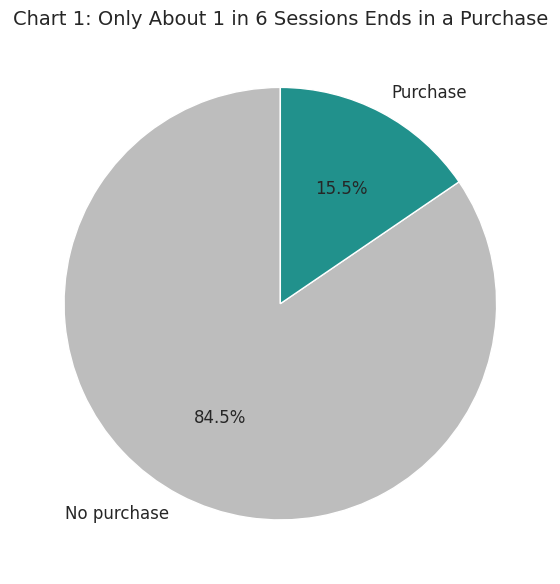

In [22]:
# Chart 1: Only a small share of sessions end in a purchase
plt.figure(figsize=(7, 6))
counts = df['Revenue'].value_counts()
plt.pie(counts, labels=['No purchase', 'Purchase'], autopct='%1.1f%%', startangle=90,
        colors=['#bdbdbd', '#21918c'], wedgeprops={'edgecolor': 'white'}, textprops={'fontsize': 12})
plt.title('Chart 1: Only About 1 in 6 Sessions Ends in a Purchase', fontsize=14)
plt.tight_layout(); plt.show()

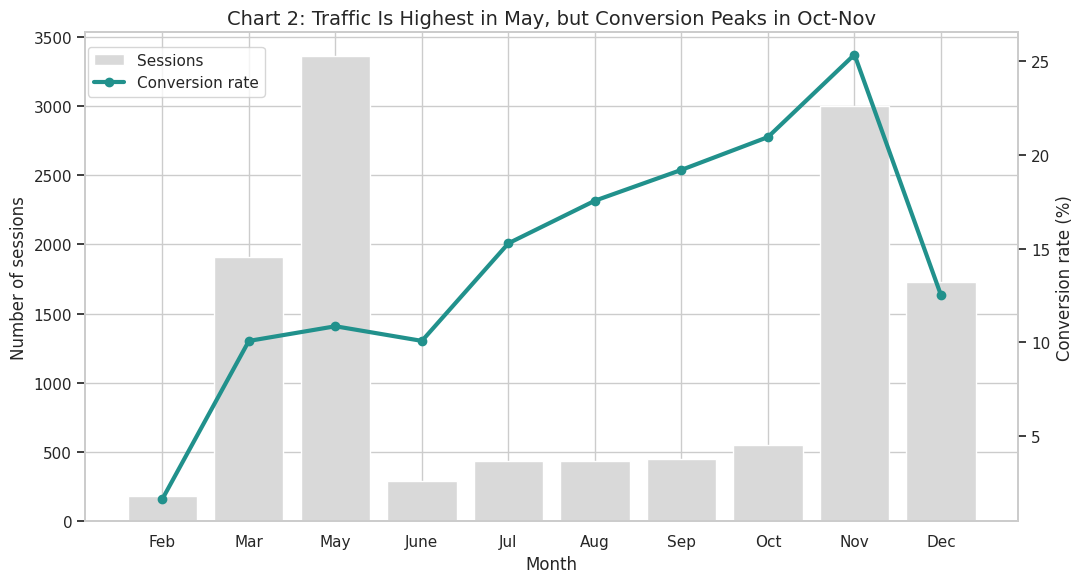

In [23]:
# Chart 2: Conversion by month (with traffic volume)
month_order = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
conv = df.groupby('Month')['Revenue'].agg(['mean', 'size']).reindex(month_order)
fig, ax1 = plt.subplots(figsize=(11, 6))
ax1.bar(conv.index, conv['size'], color='#d9d9d9', label='Sessions')
ax1.set_ylabel('Number of sessions'); ax1.set_xlabel('Month')
ax2 = ax1.twinx()
ax2.plot(conv.index, conv['mean'] * 100, color='#21918c', marker='o', linewidth=3, label='Conversion rate')
ax2.set_ylabel('Conversion rate (%)')
ax2.grid(False)
plt.title('Chart 2: Traffic Is Highest in May, but Conversion Peaks in Oct-Nov', fontsize=14)
fig.legend(loc='upper left', bbox_to_anchor=(0.08, 0.92))
plt.tight_layout(); plt.show()

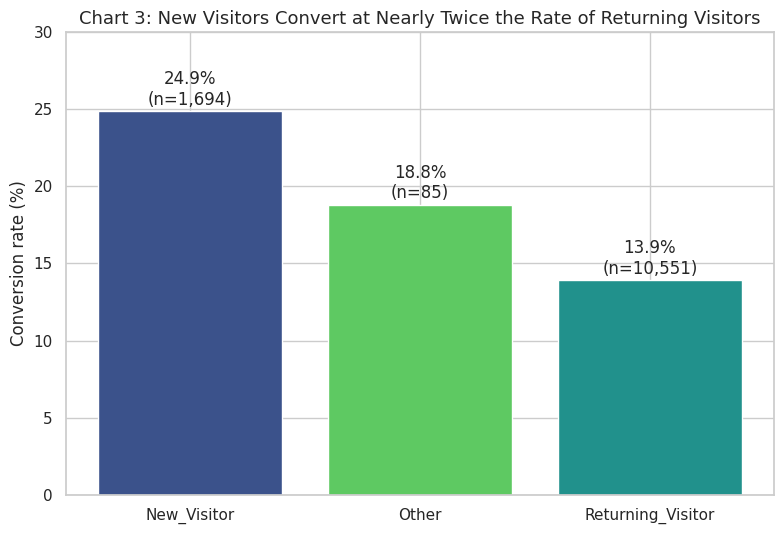

In [24]:
# Chart 3: Visitor type
vt = df.groupby('VisitorType')['Revenue'].agg(['mean', 'size'])
plt.figure(figsize=(8, 5.5))
bars = plt.bar(vt.index, vt['mean'] * 100, color=['#3b528b', '#5ec962', '#21918c'])
for b, n in zip(bars, vt['size']):
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.4, f"{b.get_height():.1f}%\n(n={n:,})", ha='center')
plt.ylabel('Conversion rate (%)'); plt.ylim(0, 30)
plt.title('Chart 3: New Visitors Convert at Nearly Twice the Rate of Returning Visitors', fontsize=13)
plt.tight_layout(); plt.show()

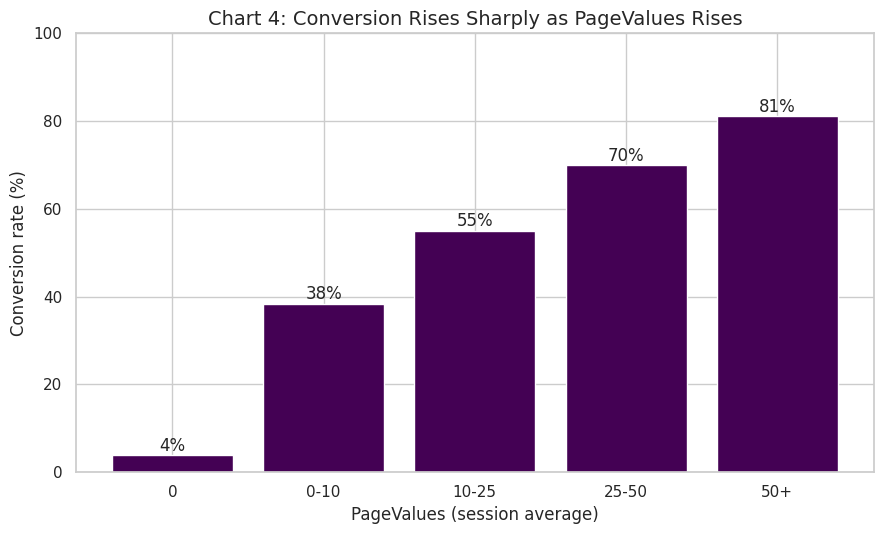

In [25]:
# Chart 4: PageValues is the strongest separator
plt.figure(figsize=(9, 5.5))
bins = pd.cut(df['PageValues'], bins=[-0.01, 0, 10, 25, 50, 400], labels=['0', '0-10', '10-25', '25-50', '50+'])
rate = df.groupby(bins, observed=True)['Revenue'].mean() * 100
bars = plt.bar(rate.index.astype(str), rate.values, color='#440154')
for b in bars:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 1, f"{b.get_height():.0f}%", ha='center')
plt.xlabel('PageValues (session average)'); plt.ylabel('Conversion rate (%)'); plt.ylim(0, 100)
plt.title('Chart 4: Conversion Rises Sharply as PageValues Rises', fontsize=14)
plt.tight_layout(); plt.show()

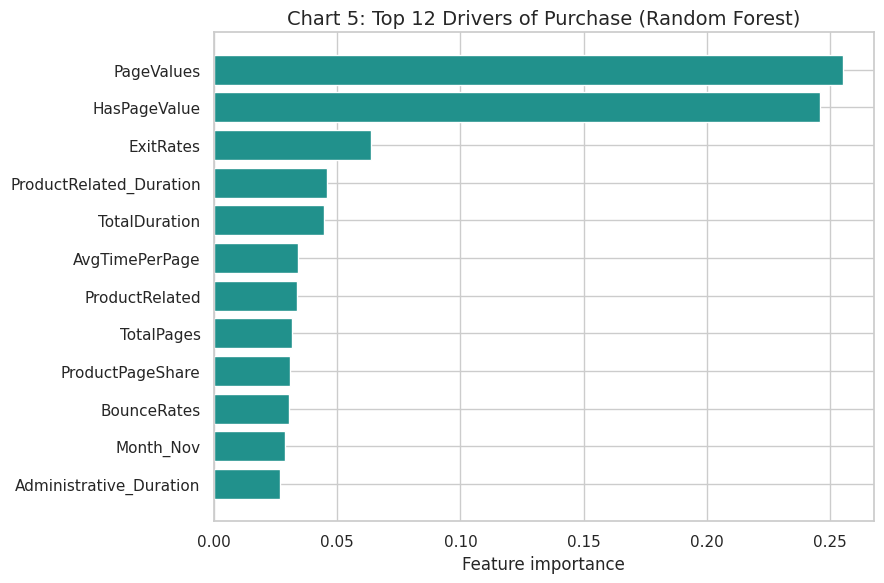

In [26]:
# Chart 5: Feature importance from the tuned Random Forest
top = importances.head(12)[::-1]
plt.figure(figsize=(9, 6))
plt.barh(top.index, top.values, color='#21918c')
plt.xlabel('Feature importance')
plt.title('Chart 5: Top 12 Drivers of Purchase (Random Forest)', fontsize=14)
plt.tight_layout(); plt.show()

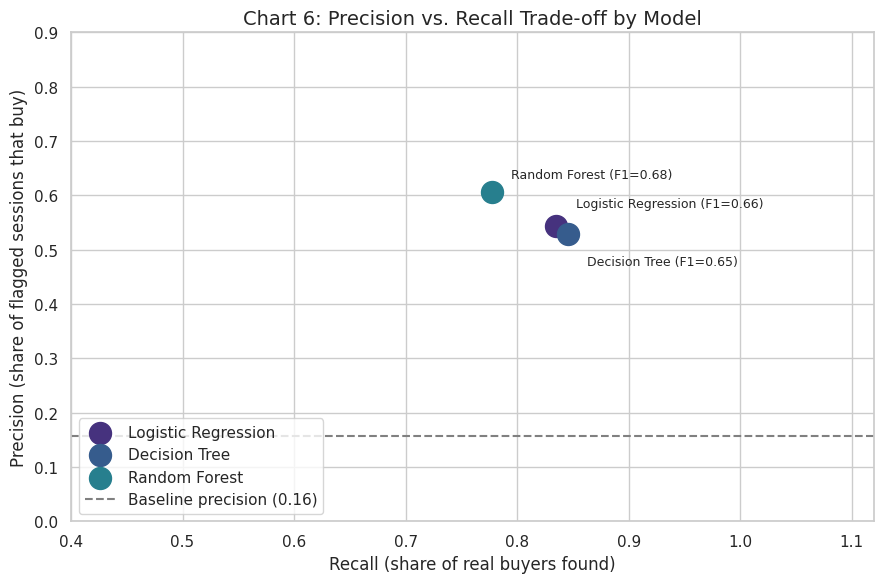

In [27]:
# Chart 6: Final model comparison on recall and precision (the business trade-off)
plt.figure(figsize=(9, 6))
offsets = {'Logistic Regression': (14, 14), 'Decision Tree': (14, -22), 'Random Forest': (14, 10)}
for name, row in results.iterrows():
    plt.scatter(row['Recall'], row['Precision'], s=250, label=name)
    plt.annotate(f"{name} (F1={row['F1']:.2f})", (row['Recall'], row['Precision']),
                 textcoords='offset points', xytext=offsets.get(name, (10, 8)), fontsize=9,
                 ha='left')
plt.axhline(y_test.mean(), color='grey', linestyle='--', label=f'Baseline precision ({y_test.mean():.2f})')
plt.xlabel('Recall (share of real buyers found)'); plt.ylabel('Precision (share of flagged sessions that buy)')
plt.xlim(0.4, 1.12); plt.ylim(0.0, 0.9)
plt.title('Chart 6: Precision vs. Recall Trade-off by Model', fontsize=14)
plt.legend(loc='lower left')
plt.tight_layout(); plt.show()

### References
1. Baymard Institute. *Cart Abandonment Rate Statistics.* https://baymard.com/lists/cart-abandonment-rate
2. Sakar, C. O., Polat, S. O., Katircioglu, M., & Kastro, Y. (2019). Real-time prediction of online shoppers' purchasing intention using multilayer perceptron and LSTM recurrent neural networks. *Neural Computing and Applications, 31*(10), 6893-6908. https://doi.org/10.1007/s00521-018-3523-0
3. U.S. Census Bureau. *Quarterly Retail E-Commerce Sales, 2nd Quarter 2026.* https://www.census.gov/retail/ecommerce.html
4. UCI Machine Learning Repository. *Online Shoppers Purchasing Intention Dataset.* https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset